# 01 — Exploración del dataset

Primer notebook del pipeline. Objetivo: abrir un video de prueba,
ver metadatos (duración, fps, resolución, cantidad total de frames)
y previsualizar cómo se verán los **16 frames** que el modelo
MobileNetV2+LSTM va a consumir.

No entrena nada: es exploración para calibrar el pipeline de
preprocesamiento antes de implementarlo en `src/preprocessing/`.

## Fuente del video

Usamos un clip de **RWF-2000**, el dataset principal del proyecto: 2000
clips de 5 s grabados por cámaras de vigilancia reales, mitad con peleas
y mitad sin. Elegimos un video de la clase `Fight` porque es la clase que
el modelo tiene que aprender a detectar.

> M. Cheng, K. Cai y M. Li, "RWF-2000: An Open Large Scale Video Database
> for Violence Detection", *25th International Conference on Pattern
> Recognition (ICPR)*, 2020.

Descarga: registro de Zenodo https://zenodo.org/records/15687512, con
licencia CC BY 4.0. El video **no se versiona** (`data/raw/` está en
`.gitignore`); ver `data/README.md` para obtenerlo.

## 1. Imports

- `cv2` (OpenCV) para leer el video frame a frame.
- `numpy` para el muestreo determinista de índices.
- `matplotlib` para la grilla 4x4 de previsualización.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 2. Configuración

`VIDEO_PATH` apunta al clip `_2RYnSFPD_U_0.avi` de RWF-2000. La ruta
es relativa a `notebooks/`, que es el directorio desde donde corre el
kernel. Lo dejamos como variable arriba para no tener que buscar la
cadena en medio del notebook.

`NUM_FRAMES = 16` porque:

- Es el estándar de modelos de clasificación de acciones (I3D, TSN,
  SlowFast en su versión chica). Nos da suficiente información
  temporal sin que el LSTM se vuelva demasiado caro en memoria.
- Encaja exacto en una grilla **4x4**, útil para inspección visual.
- Para clips cortos (3-5 segundos típicos del dataset) 16 frames
  cubren bien la secuencia completa sin apenas redundancia.

In [2]:
# Clip de la clase Fight de RWF-2000. En la copia del Drive la carpeta
# se llama Train_Fight: ajustar la ruta si tu copia local usa ese nombre.
VIDEO_PATH = '../data/raw/rwf2000/train/Fight/_2RYnSFPD_U_0.avi'

# Cantidad de frames que extraemos por video.
# Ver la celda anterior para la justificacion.
NUM_FRAMES = 16

## 3. Metadatos del video

Antes de muestrear, inspeccionamos el video crudo. Esto sirve para:

- Verificar que OpenCV puede abrirlo (si el codec no es compatible
  `cap.isOpened()` devuelve `False` y tenemos que reencodear).
- Decidir si hace falta normalizar la duración o la resolución
  antes de pasarlo al modelo.

In [3]:
# Abrimos el video con OpenCV. VideoCapture acepta ruta o indice
# de camara; aqui vamos con ruta a archivo.
cap = cv2.VideoCapture(VIDEO_PATH)

# Si la ruta esta mal o el codec no es compatible, VideoCapture no lanza
# error: devuelve un objeto cerrado y todas las propiedades valen 0.
# Cortamos aqui con un mensaje claro en vez de fallar mas abajo con
# indices negativos en np.linspace.
if not cap.isOpened():
    raise IOError(f'No se pudo abrir el video: {VIDEO_PATH}')

# cv2.CAP_PROP_* son enteros que identifican cada propiedad.
# Usamos los nombres por legibilidad.
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Duracion en segundos = frames totales / fps.
# Si fps es 0 (video corrupto o metadata rota) evitamos la division.
duration = total_frames / fps if fps > 0 else 0.0

print(f'Ruta:        {VIDEO_PATH}')
print(f'Resolucion:  {width} x {height}')
print(f'FPS:         {fps:.2f}')
print(f'Frames tot.: {total_frames}')
print(f'Duracion:    {duration:.2f} s')

Ruta:        ../data/raw/rwf2000/train/Fight/_2RYnSFPD_U_0.avi
Resolucion:  1280 x 720
FPS:         30.00
Frames tot.: 150
Duracion:    5.00 s


## 4. Extracción de 16 frames espaciados uniformemente

Usamos `np.linspace(0, total_frames - 1, NUM_FRAMES)` y convertimos
a `int`. ¿Por qué este muestreo y no uno aleatorio?

- **Determinista**: dos ejecuciones distintas producen los mismos
  frames. Si el modelo clasifica mal un video, podemos reproducir
  exactamente qué vio.
- **Cobertura completa**: espaciado uniforme garantiza que vemos
  principio, medio y final del clip. Un muestreo aleatorio podría,
  por mala suerte, concentrarse en un tramo.
- **El muestreo aleatorio tiene sentido como \"data augmentation\"
  durante entrenamiento**, no en exploración ni en inferencia.

Después de leer cada frame hacemos `cvtColor` **BGR → RGB** porque
OpenCV devuelve BGR (herencia histórica) y matplotlib dibuja asumiendo
RGB. Si lo saltamos, los colores salen invertidos.

In [4]:
# np.linspace nos da NUM_FRAMES puntos equiespaciados en el rango
# [0, total_frames - 1]. Convertimos a entero porque los indices
# de frame tienen que ser enteros.
frame_indices = np.linspace(0, total_frames - 1, NUM_FRAMES).astype(int)
print('Indices de frames a extraer:', frame_indices)

frames = []
for idx in frame_indices:
    # Posicionamos el puntero de lectura en el frame deseado.
    # Es menos eficiente que leer secuencialmente pero mas simple;
    # para videos cortos (<30s) el costo es despreciable.
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, frame = cap.read()
    if not ret:
        # Si el seek falla saltamos ese indice; el pipeline final
        # debera manejar esto (p.ej. repetir el ultimo frame valido).
        print(f'Advertencia: no se pudo leer el frame {idx}')
        continue
    # OpenCV lee en BGR; matplotlib espera RGB. Convertimos aqui.
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append(frame_rgb)

# Liberamos el handle del archivo. Si no lo hacemos, en Windows
# el archivo queda bloqueado hasta que muera el kernel del notebook.
cap.release()

print(f'Frames extraidos: {len(frames)} / {NUM_FRAMES}')

Indices de frames a extraer: [  0   9  19  29  39  49  59  69  79  89  99 109 119 129 139 149]


Frames extraidos: 16 / 16


## 5. Visualización en grilla 4x4

Mostramos los 16 frames en una grilla 4x4 con el índice de cada uno
como título. Esto nos permite confirmar visualmente que el muestreo
cubre toda la acción del clip y que los frames se ven "razonables"
(no en negro, no con compresión rota).

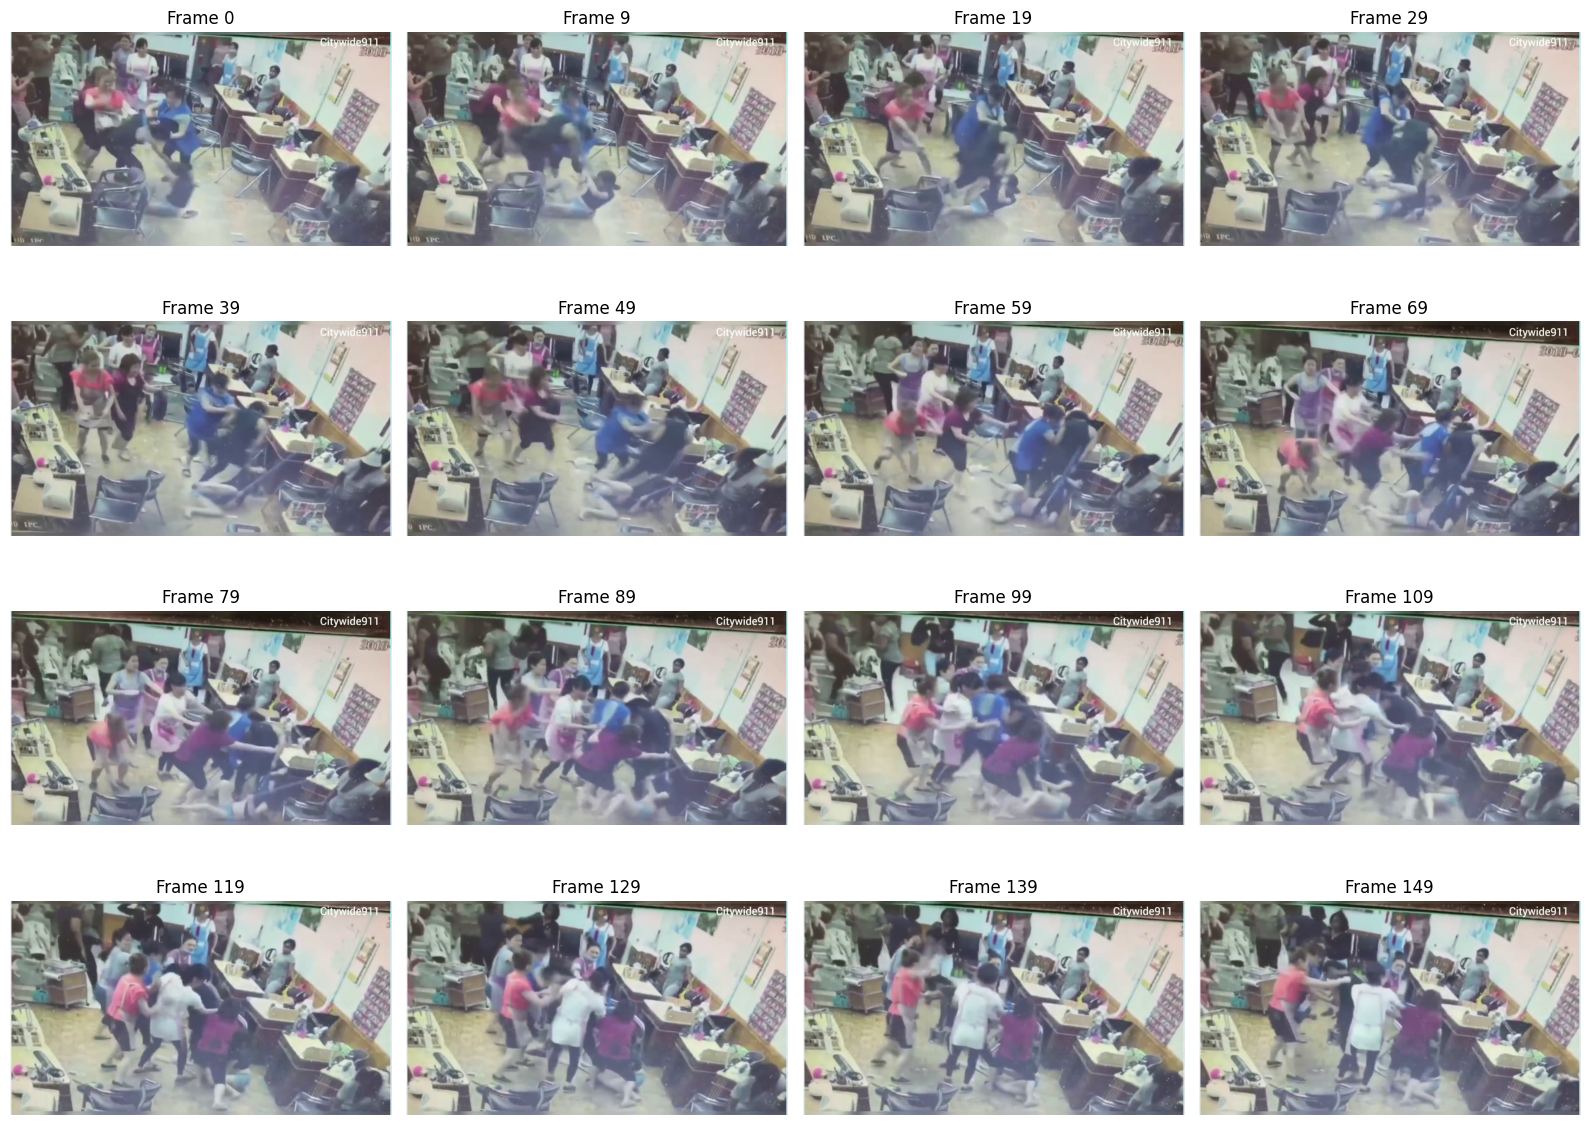

In [5]:
# figsize generoso para que las miniaturas sean legibles.
fig, axes = plt.subplots(4, 4, figsize=(16, 12))

# .flatten() nos deja iterar los 16 ejes como lista plana en vez
# de recorrer dos indices (fila, columna).
for ax, frame, idx in zip(axes.flatten(), frames, frame_indices):
    ax.imshow(frame)
    ax.set_title(f'Frame {idx}')
    # Quitamos los ejes: no aportan informacion en imagenes.
    ax.axis('off')

plt.tight_layout()
plt.show()

## 6. Próximos pasos

- Portar la lógica de extracción a `src/preprocessing/frames.py` como
  función reusable (tipada, con docstring).
- Agregar redimensionado a 224x224 (entrada que espera MobileNetV2).
- Agregar normalización con la media/std de ImageNet.
- Test en `tests/test_frames.py` que verifique que para un video de
  prueba se extraen exactamente 16 frames con los índices esperados.